# 01 · Data Understanding

Getting to know every table. The notes for each table are also in `docs/project_notes.md` (section *Tables*).

In [ ]:
import sys
from pathlib import Path
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_loading import load_all, overview, build_sqlite

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
FIG = Path("../figures"); FIG.mkdir(exist_ok=True)   # plots for the slides are saved here

tables = load_all()
overview(tables)

## Table by table

Run the next cell once, then each table's cell.

In [ ]:
def describe_table(name):
    """Short summary of one table: size, years, first rows, and one line per column."""
    df = tables[name]
    years = f"{df['year'].min()}–{df['year'].max()}" if "year" in df else "no year column"
    print(f"{name}: {len(df)} rows, {df.shape[1]} columns, {years}")
    display(df.head(3))
    display(pd.DataFrame({
        "type": df.dtypes.astype(str),
        "missing_%": (df.isna().mean() * 100).round(0),
        "example": df.apply(lambda col: col.dropna().iloc[0] if col.notna().any() else None),
        "min": df.min(numeric_only=True),
        "max": df.max(numeric_only=True),
    }).reindex(df.columns))

### Teams

**One row** = a team in a season, 1909–2009. **Use:** (a) core: `rank` (what we predict), points, goals.

- Empty `playoff` = the team missed the playoffs, not missing data.
- Some columns only exist in later years: power play from 1963, `OTL` from 1999, shootouts from 2005. `T` (ties) empty after 2004.
- `rank` reaches 10 in old seasons; divisions used to be bigger (8 teams in the 1970s), now 5.
- Odd rows (outliers): WHA national teams 1977–78 (Czechoslovakia, Soviet All Stars, Finland; 1–8 games) and Montreal Wanderers 1917 (6 games, arena burned down).
- Average `GF` = average `GA` (every goal scored is conceded by someone): consistent.

In [ ]:
describe_table("Teams")

### Coaches

**One row** = a coach's spell with a team in a season, 1909–2009. **Use:** (b) core: the coach-change answer is built from here.

- `stint` = order of coaches in that season (1 = first).
- 9 interim coaches, 1 co-coach case (DET 1998).
- Playoff columns (`post…`) empty for about half the rows = team missed the playoffs.

In [ ]:
describe_table("Coaches")

### Scoring

**One row** = a player's spell with a team in a season, 1909–2009. **Use:** (a): how good each roster is.

- About 35 players per team per season.
- `stint` 2+ = player joined the team during the season.
- Advanced stats (power play, `+/-`, shots) missing in old seasons; playoff columns empty for players who didn't play playoffs.

In [ ]:
describe_table("Scoring")

### Goalies

**One row** = a goalie's spell with a team in a season, 1909–2009. **Use:** (a): goalie quality.

- Shots against (`SA`) missing in 39% of rows (not recorded in old seasons).

In [ ]:
describe_table("Goalies")

### Master

**One row** = one person (player and/or coach). No year column. **Use:** age, experience (`firstNHL`), height/weight.

- Linked by `playerID` and `coachID`. 268 people were both player and coach; 124 only coaches.
- Death columns mostly empty (most people are alive).

In [ ]:
describe_table("Master")

### TeamsPost

**One row** = a team's playoff totals in a season, 1913–2009. **Use:** how far a team went in last season's playoffs.

- Only teams that made the playoffs appear.

In [ ]:
describe_table("TeamsPost")

### SeriesPost

**One row** = one playoff series (winner, loser, games), 1912–2009. **Use:** same as TeamsPost, round by round.

In [ ]:
describe_table("SeriesPost")

### TeamSplits

**One row** = a team's home/road and month-by-month record in a season, 1909–2009. **Use:** e.g. a team collapsing late in the season, home vs road form.

- September columns always empty; overtime-loss columns only in recent years.

In [ ]:
describe_table("TeamSplits")

### TeamVsTeam

**One row** = a team's record against one opponent in a season, 1909–2009. **Use:** probably low.

In [ ]:
describe_table("TeamVsTeam")

### AwardsCoaches

**One row** = an award won by a coach, 1930–2009 (75 rows). **Use:** (b): do award-winning coaches keep their jobs?

In [ ]:
describe_table("AwardsCoaches")

### AwardsPlayers

**One row** = an award won by a player, 1917–2009. **Use:** (a): star players on a roster.

In [ ]:
describe_table("AwardsPlayers")

### Small or limited tables

- **AwardsMisc, HOF:** other awards and Hall of Fame. Probably low use.
- **abbrev:** list of codes and their meaning (e.g. playoff codes). Lookup only.
- **TeamsHalf** (1916–1920), **TeamsSC, ScoringSC, GoaliesSC** (1912–1925): too old to help.
- **ScoringShootout, GoaliesShootout** (2005–2009), **ScoringSup** (1987–1990): too few years to rely on.
- **CombinedShutouts:** 50 rows. Useless.

In [ ]:
for name in ["AwardsMisc", "HOF", "abbrev", "TeamsHalf", "TeamsSC", "ScoringSC", "GoaliesSC",
             "ScoringShootout", "GoaliesShootout", "ScoringSup", "CombinedShutouts"]:
    describe_table(name)

## Database (optional)

Same data in a SQLite file, queried with SQL. Only needed for the grading row *tools: database*.

In [ ]:
con = build_sqlite(tables)

pd.read_sql("""
    SELECT year, lgID, COUNT(*) AS n_teams
    FROM Teams
    GROUP BY year, lgID
    ORDER BY year DESC
    LIMIT 10
""", con)

## Plots

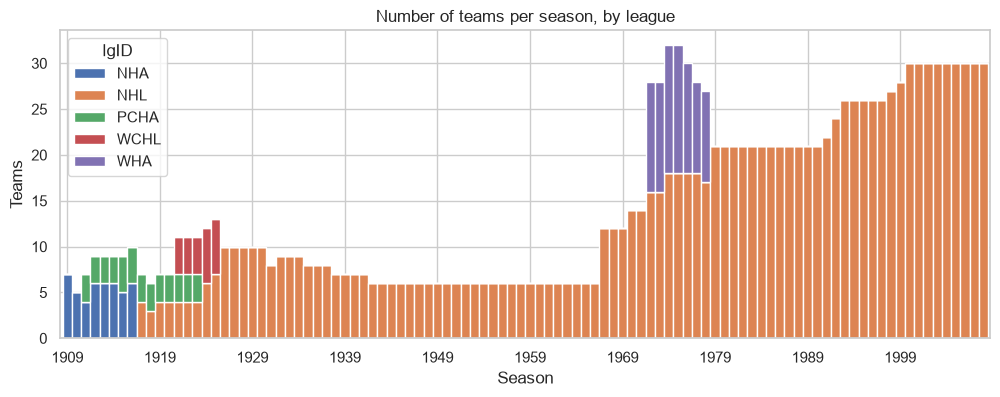

In [5]:
teams = tables["Teams"]
counts = teams.groupby(["year", "lgID"]).size().unstack(fill_value=0)
counts.plot(kind="bar", stacked=True, width=1, figsize=(12, 4))
plt.xticks(range(0, len(counts), 10), counts.index[::10], rotation=0)
plt.title("Number of teams per season, by league")
plt.ylabel("Teams"); plt.xlabel("Season")
plt.savefig(FIG / "teams_per_season.png", bbox_inches="tight"); plt.show()

The NHA, PCHA and WCHL overlapped with the early NHL until 1925, and the WHA ran alongside it from 1972 to 1978. From 1979 the NHL is the only league, growing from 21 to 30 teams by 2000.

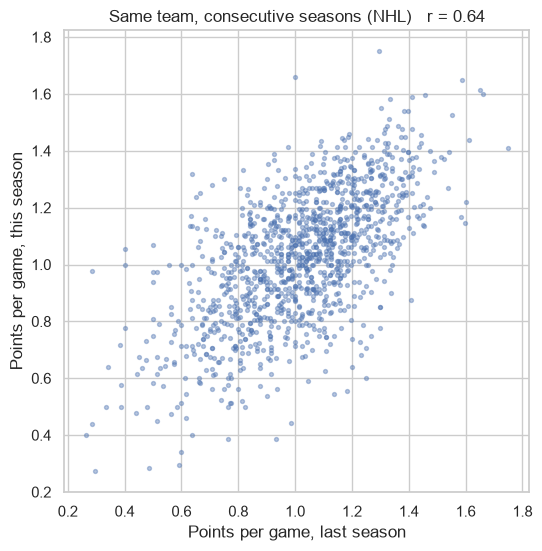

Correlation r = 0.64


In [6]:
from scipy import stats

nhl = teams[teams["lgID"] == "NHL"].copy()
nhl["pts_per_game"] = nhl["Pts"] / nhl["G"]
nhl["gf_per_game"] = nhl["GF"] / nhl["G"]
nhl["ga_per_game"] = nhl["GA"] / nhl["G"]
nhl = nhl.sort_values(["franchID", "year"])
nhl["pts_per_game_last"] = nhl.groupby("franchID")["pts_per_game"].shift(1)
pair = nhl.dropna(subset=["pts_per_game_last"])

r, p = stats.pearsonr(pair["pts_per_game_last"], pair["pts_per_game"])
plt.figure(figsize=(6, 6))
plt.scatter(pair["pts_per_game_last"], pair["pts_per_game"], s=8, alpha=0.4)
plt.xlabel("Points per game, last season"); plt.ylabel("Points per game, this season")
plt.title(f"Same team, consecutive seasons (NHL)   r = {r:.2f}")
plt.savefig(FIG / "points_last_vs_this.png", bbox_inches="tight"); plt.show()
print(f"Correlation r = {r:.2f}")

Points per game last season and this season have a correlation of 0.64: a team’s previous season is a good guide to the next one, but far from a perfect one, so other information (like roster changes) is needed.

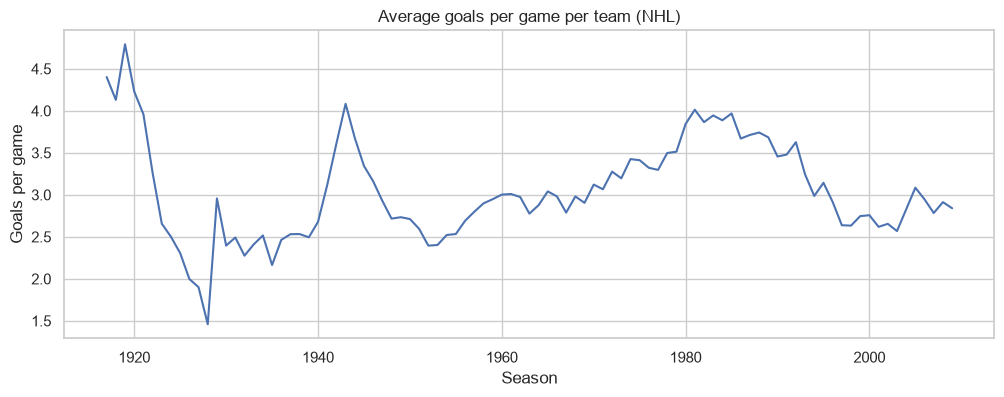

In [7]:
nhl.groupby("year")["gf_per_game"].mean().plot(figsize=(12, 4))
plt.title("Average goals per game per team (NHL)"); plt.ylabel("Goals per game"); plt.xlabel("Season")
plt.savefig(FIG / "goals_per_game.png", bbox_inches="tight"); plt.show()

Goals per game change a lot over time: very high in the first seasons, lowest in 1928 (1.5), a jump during World War II, a slow rise to a peak in the 1980s (about 4.0), then a drop to about 2.6 by the early 2000s. Even within 1979–2009, scoring levels differ, so team stats should be compared to their own season’s average.